# Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import rotate, gaussian_filter, zoom
from threadpoolctl import threadpool_limits   #limit each parallel worker to one core
import json, csv

In [2]:
import os, sys
#Getting directory for AART
AART_DIR = os.path.abspath("aart")
sys.path.insert(0, AART_DIR) 

#Record where we are, step out, import functions, and come back
cwd = os.getcwd(); os.chdir(AART_DIR)
from aart_func import lb_f, raytracing_f, intensity_f, rprofs_f
from aart_func.misc import rms
import params as aart_params
os.chdir(cwd)

#EHT-blurring library
import ehtim as eh
EHT_ARRAY = eh.array.load_txt("eht_arrays/EHT2017.txt")
SGRA_RA, SGRA_DEC = 17.761122472222223, -29.00781055   #Sgr A* [hours, degrees]
SGRA_FLUX = 2.4                                        #total 230 GHz flux [Jy]


Thanks for using AART


Welcome to eht-imaging!



In [3]:
#Noise constant-setting
FWHM_UAS = 20.      #EHT-like beam [uas]
NOISE_FRAC = 0.03   #noise std as a fraction of the blurred peak
rng = np.random.default_rng(2026)   #fixed seed -> reproducible noise

In [4]:
#Reusing the existing images to Guassina blur+noise them
sys.path.insert(0, os.path.abspath("Deniz/simple/Blurring"))
sys.path.insert(0, os.path.abspath("Deniz/simple/Noise"))
from blurring import apply_psf, pixel_size_uas
from noise import add_noise

## Define functions + constants

In [5]:
#Constants
G = 6.67e-11 #m^3/kg/s^2
c = 3e8 #m/s
M_Sun = 1.989e30 #solar masses, in kg

M_SGR = 4.3e6 #in units of M_Sun
M_M87 = 6.5e9 #in units of M_Sun 

In [6]:
def r_m(a): #return r_- in units of M
	return 1 - np.sqrt(1. - a*a)

def r_ISCO(a): #return innermost stable circular orbit
	Z1 = 1. + (1.-a*a)**(1./3.)*((1.+a)**(1./3.) + (1.-a)**(1./3.))
	Z2 = np.sqrt(3.*a*a + Z1*Z1)
	rISCO = 3. + Z2 - np.sqrt((3.-Z1)*(3.+Z1+2.*Z2))
	return rISCO

In [7]:
#--------------Constants set from paper-----------------#
f_udge = 1.5
#Use single frequency emission
p = 3
vel_params = [1., 1., 1.] #xi, beta_r, beta_phi

#------------Imaging constants---------------#
#Make (square) image -L/2 -> L/2, after cropping
L = 40 #in M
#Pixel size
dx_n = [0.1, 0.1, 0.1] #dx_0, dx_1, dx_2
#Saved images are downsampled to NPIX_OUT x NPIX_OUT (~3.3 uas pixels, EHT-image scale)
NPIX_OUT = 64
#Ray tracing boundary, just needs to be >> 100M
D_obs = 1e5 #in M
#Distance to black hole, only affects uas conversion
D_BHs = [2.5e20, 5.2e23] #Sgr A*, M87* in m
D_BH = D_BHs[0] #Just keep it constant for images
psi_0 = 6.2e9

In [8]:
def buildParams(M, a, theta_inc, p_image=1):
	'''
	Purpose: Build parameter list needed for creating images
	Inputs: 
		M: mass of BH, required for uas conversion (and nothing else)
		a: spin of BH, from 0-1
		theta_inc: viewing/inclination angle, in degrees
		p_image: whether all the images are on the same grid. Default 1 (true)
	Returns: 
		params: dictionary with 18 items (parameters)'''
	params = {}

	params["spin_case"] = a
	params["thetao"] = theta_inc * np.pi/180.
	params["gammap"] = -1.5
	params["mup"] = r_m(a)
	params["sigmap"] = 0.5
	params["fudge"] = f_udge
	params["gfactor"] = p
	params["sub_kep"] = vel_params[0]
	params["betar"] = vel_params[1]
	params["betaphi"] = vel_params[2]
	params["limits"] = L
	params["dxn"] = dx_n
	params["D_obs"] = D_obs
	psi = M/psi_0; #in units of per 6.2e9
	params["psi"] = psi
	params["dBH"] = D_BH
	params["p_image"] = p_image

	params["i_case"] = theta_inc
	params["isco"] = r_ISCO(a)
    
    
	return params

In [9]:
def normalizeImage(image): #normalize to sum, not peak
	return image/np.sum(image)

def rotateImage(image, rot_angle, turns=0):
	if(turns!=0): 
		rotated = np.rot90(image, turns)
	else: 
		rotated = rotate(image, rot_angle, reshape=False, order=1)
	return rotated

def downsampleImage(image, axis, npix_out=NPIX_OUT):
	'''Downsample to npix_out x npix_out over the same field of view.
	Returns the image (sum = 1) and its pixel-center axis [r_g]'''
	N = image.shape[0]
	factor = N/npix_out
	#Smooth over ~half a new pixel first so thin rings are averaged, not skipped
	smooth = gaussian_filter(image, 0.5*factor, mode="constant")
	small = zoom(smooth, npix_out/N, order=1, grid_mode=True, mode="grid-constant")
	small = normalizeImage(np.clip(small, 0., None))
	#New pixel centers: npix_out equal pixels spanning the same edges
	W = axis[-1] + 0.5*(axis[1]-axis[0])       #half-width to the image edge
	dx = 2*W/npix_out
	return small, -W + dx*(np.arange(npix_out) + 0.5)

### Image creation + blurring

In [10]:
def set_aart(**values):
	'''Need to set the parameter values across every module, 
	at the same time, hence this function'''
	for module in [aart_params, lb_f, raytracing_f, intensity_f, 
				   rprofs_f]:
		for name, value in values.items():
			setattr(module, name, value)

def generateImage(params):
	#Initialize all the parameters
	set_aart(**params)
	a = params["spin_case"]
	inc = params["i_case"]

	#Calculate x (alpha) and y (beta) coords of image
	alpha_c, beta_c = lb_f.spacedmarks(*lb_f.CritCurve(a, inc), 
			aart_params.npointsS)
	#Inner and outer edge for n = 0, 1, 2
	hulls = lb_f.hulls(alpha_c, beta_c) #boundaries for lensing band

	image = 0
	for n in range(3):
		#Calculates (alpha, beta) array, pixels per side, T/F if each pixel
		#lies inside this band, half-width
		grid, N, mask, lim = lb_f.grid_mask(hulls[2*n], hulls[2*n+1],
					params["dxn"][n], params["limits"], True)

		#Raytracing part, calculates radius where ray crosses disk for 
		#the n+1-th time, and sign = +/- for light moving out/in
		r_s, sign, _, _ = raytracing_f.calculate_observables(
			grid, mask, params["thetao"], a, n, distance=params["D_obs"])
    
		#Calculate intensity for each pixel = g^p * J(r_s)
		I_n = intensity_f.bright_radial(grid, mask, sign, a, r_s, 
						params["isco"], params["thetao"])
		I_n = I_n.reshape(N, N).T

		#f_n behavior
		if(n == 0):
			weight = 1
		else:
			weight = params["fudge"]
		image = image + weight*np.nan_to_num(I_n)
    
	return image

In [11]:
def eht_reconstruct(image, psize_uas, npix_out=NPIX_OUT, seed=1, rounds=3, maxit=200):
	'''EHT-style image (pipeline C): observe with the EHT 2017 array, then
	reconstruct with regularized maximum likelihood (RML) imaging in ehtim.
	Returns the reconstructed image (npix_out x npix_out, same field of view) and the observation'''
	N = image.shape[0]
	fov_rad = N*psize_uas*eh.RADPERUAS
	im = eh.image.Image(np.flipud(image/image.sum()*SGRA_FLUX), psize_uas*eh.RADPERUAS,
			SGRA_RA, SGRA_DEC, rf=230e9, source="SgrA")
	#Simulated EHT observation: visibilities on the 2017 (u,v) tracks + thermal noise
	#(seed must be nonzero: ehtim treats 0 as "no seed")
	obs = im.observe(EHT_ARRAY, tint=60, tadv=600, tstart=0, tstop=24, bw=4e9,
			add_th_noise=True, ampcal=True, phasecal=True,
			ttype="fast", fft_pad_factor=2, seed=seed, verbose=False)
	beam = obs.fit_beam()
	#Starting guess / prior: a 60 uas Gaussian with the total flux
	prior = eh.image.make_square(obs, npix_out, fov_rad).add_gauss(SGRA_FLUX,
			(60*eh.RADPERUAS, 60*eh.RADPERUAS, 0, 0, 0))
	init = prior
	#RML imaging: fit the data + regularizers, blur by half a beam, repeat
	for r in range(rounds):
		imgr = eh.imager.Imager(obs, init, prior_im=prior, flux=SGRA_FLUX,
				data_term={"vis": 1}, reg_term={"simple": 100, "tv2": 10, "flux": 100},
				maxit=maxit, ttype="direct", clipfloor=-1, norm_reg=True, show_updates=False)
		imgr.make_image_I(show_updates=False)
		out = imgr.out_last()
		init = out.blur_circ(0.5*beam[1])
	return np.flipud(out.imvec.reshape(npix_out, npix_out)), obs

In [12]:
def crop_image(image, L_in, L_out):
	'''
	Purpose: crops image to [-L_out, L_out]
	Inputs:
		image: 2D array of pixel color values
		L_in: half-width of input image
		L_out: half-width of output image'''
	N = image.shape[0]
	axis = np.linspace(-L_in, L_in, N)
	keep = np.abs(axis) <= L_out
	im_cropped = image[np.ix_(keep, keep)]
	ax_cropped = axis[keep]
	return im_cropped, ax_cropped

def plot_image(image, parms, lowlim = 2.5):
	#Get the high and low of image
	log_hi = np.log10(image.max())
	high = 10**(np.ceil(log_hi))
	low = 10**(-lowlim) * high
	#Clip image to reasonable values
	image = np.clip(image, low, None)
	#Plot image
	fig, ax = plt.subplots() #figsize=(5.5,4.5)
	im = ax.imshow(image, origin="lower", extent=0.5*np.array([-L,L,-L,L]), 
		cmap="afmhot", norm=LogNorm(low, high))
	cbar = fig.colorbar(im, ax=ax)
	#Set up labels
	cbar.set_label(r"$I_{obs}$")
	ax.set_xlabel(r"$\alpha$ $(r_g)$")
	ax.set_ylabel(r"$\beta$ $(r_g)$")
	ax.set_title(fr"$a = {parms['spin_case']:.3f}$, $i = {parms['i_case']:.1f}^\circ$")
	plt.show()

In [13]:
def plot_stages(images, titles, half_width, parms, lowlim=2.5, log=True):
	'''Plot images side by side; log=True uses a log scale (lowlim decades), log=False a linear scale'''
	fig, axs = plt.subplots(1, len(images), figsize=(5*len(images), 4))
	for a_, image, t in zip(axs, images, titles):
		if log:
			#Get the high and low of each image
			high = 10**(np.ceil(np.log10(image.max())))
			low = 10**(-lowlim) * high
			#Clip image to reasonable values (also removes negatives from noise/sidelobes)
			image = np.clip(image, low, None)
			norm = LogNorm(low, high)
		else:
			#Linear scale from the minimum (keeps negative noise/sidelobes visible) to the peak
			norm = plt.Normalize(min(image.min(), 0.), image.max())
		#Plot image
		im = a_.imshow(image, origin="lower", cmap="afmhot", norm=norm,
				extent=[-half_width, half_width, -half_width, half_width])
		cbar = fig.colorbar(im, ax=a_)
		cbar.set_label(r"$I_{obs}$")
		a_.set_title(t)
		a_.set_xlabel(r"$\alpha$ $(r_g)$")
	axs[0].set_ylabel(r"$\beta$ $(r_g)$")
	fig.suptitle(fr"$a = {parms['spin_case']:.3f}$, $i = {parms['i_case']:.1f}^\circ$")
	plt.tight_layout()
	plt.show()

## Test image creation + blurring

In [14]:
pms = buildParams(M_SGR, a=0.9, theta_inc=60)
img = normalizeImage(generateImage(pms)) #takes ~30 seconds per image
clean, ax = crop_image(img, L, L/2)
clean, ax = downsampleImage(clean, ax)   #64 x 64, same field of view

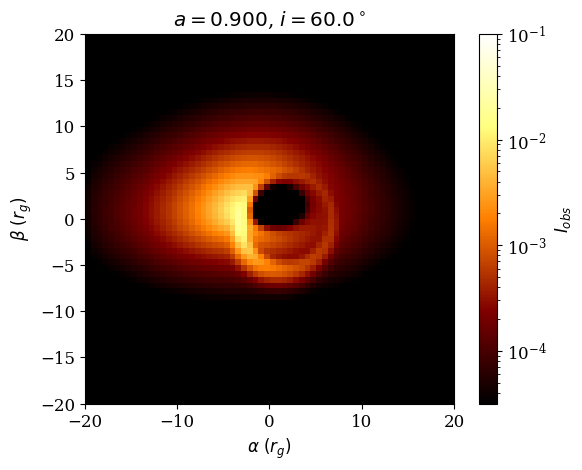

In [15]:
plot_image(clean, pms, 3.5)

In [16]:
M_bh = pms["psi"]*psi_0
theta_g = G*M_bh*M_Sun/(c**2*pms["dBH"]) * (180./np.pi*3600.*1e6)
psize_uas = (ax[1]-ax[0])*theta_g

blurred = apply_psf(clean, FWHM_UAS, psize_uas)
gauss, noise_std = add_noise(blurred, NOISE_FRAC, blurred.max(), np.random.default_rng(0))
eht, obs = eht_reconstruct(clean, psize_uas, seed=1)      #~15-60 s
eht = normalizeImage(eht)

Initializing imager data products . . .


Imager run 1 
Imaging . . .


time: 12.848210 s
J: 88.735620
chi2_vis : 9.41 
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
Initializing imager data products . . .


Imager run 1 
Imaging . . .


time: 13.287939 s
J: 84.146182
chi2_vis : 6.71 
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
Initializing imager data products . . .


Imager run 1 
Imaging . . .


time: 13.659474 s
J: 82.783063
chi2_vis : 6.24 
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


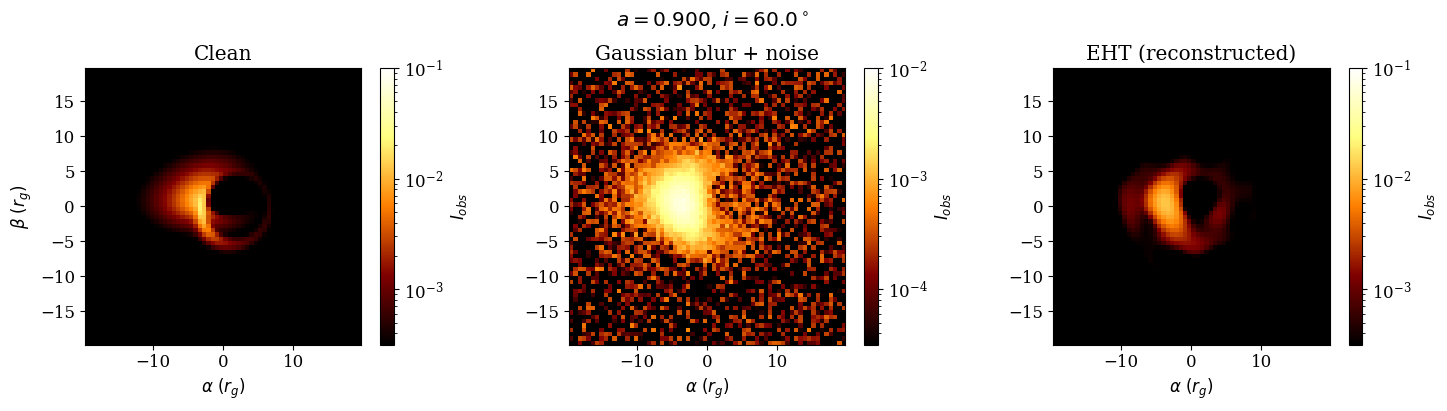

In [17]:
plot_stages([clean, gauss, eht], ["Clean", "Gaussian blur + noise", "EHT (reconstructed)"],
		ax[-1], pms)

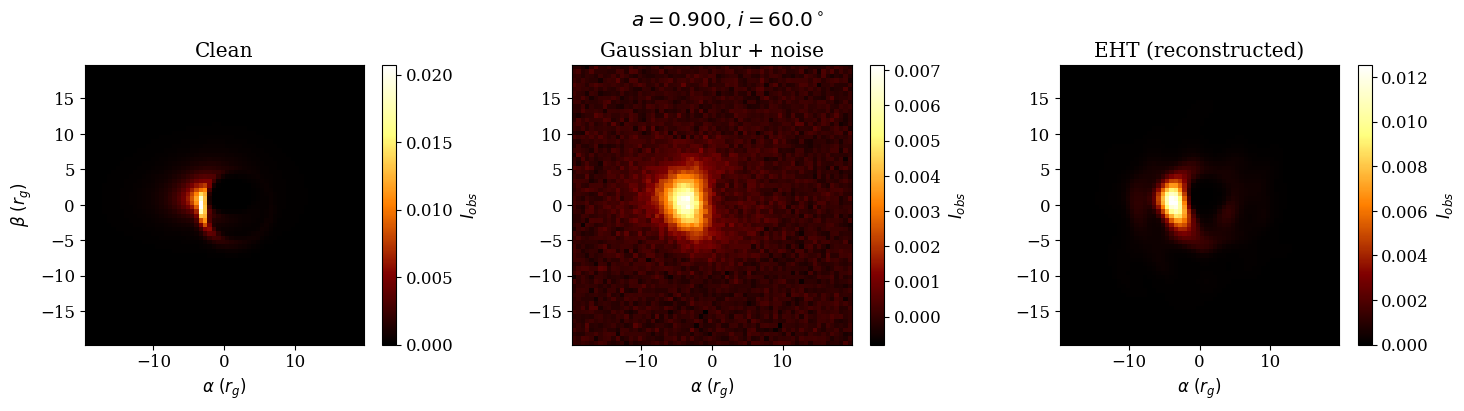

In [18]:
plot_stages([clean, gauss, eht], ["Clean", "Gaussian blur + noise", "EHT (reconstructed)"],
		ax[-1], pms, log=False)

# Create Dataset

In [19]:
#Make the data directory if it doesn't exist already
IMG_DIR = "dataset" 
os.makedirs(IMG_DIR, exist_ok=True) 

#One for clean images
CLEAN_DIR = os.path.join(IMG_DIR, "clean_imgs")
os.makedirs(CLEAN_DIR, exist_ok=True)

#One for Gaussian blurred + noisy images
BLUR_DIR = os.path.join(IMG_DIR, "blurredNnoisy_imgs")
os.makedirs(BLUR_DIR, exist_ok=True)

#One for the EHT-blurred images
EHT_DIR = os.path.join(IMG_DIR, "EHTblurred_imgs")
os.makedirs(EHT_DIR, exist_ok=True)

In [20]:
def save_image(image, axis, parameters, ID, j_a, j_inc, out_dir=CLEAN_DIR):
	N = image.shape[0]
	#Copy parameters to local vars
	params = dict(parameters)
	M = params["psi"]*psi_0   # solar masses
	theta_g_rad = G*M*M_Sun/(c**2*params["dBH"]) # GM/(c^2 D), radians
	rad_to_uas = 180./np.pi*3600.*1e6
	theta_g_uas = theta_g_rad*rad_to_uas

	#Update the metadata
	params.update(id=ID, j_a=j_a, j_inc=j_inc, npix=N, 
			limits=axis[-1], # correct image half-width
			theta_g_uas=theta_g_uas, #angular size of an r_g on the sky
			normalization="sum = 1") 
	name = f"img_{ID:06d}.npz"

	#Save the image
	np.savez_compressed(os.path.join(out_dir,name),
			image=image.astype(np.float32), alpha_rg=axis, beta_rg=axis,
			meta=json.dumps(params)) 
	#Give back this image's row
	return dict(id=ID, file=name, j_a=j_a, j_inc=j_inc, 
			spin=params['spin_case'], inc_deg=params['i_case'], 
			cos_inc = np.cos(params['thetao']))

def write_index(rows, DIR):
	with open(os.path.join(DIR, "index.csv"), "w", newline="") as fh:
		w = csv.DictWriter(fh, fieldnames = list(rows[0]))
		w.writeheader()
		w.writerows(rows)

In [21]:
def image_by_idx(idx, img_dir=CLEAN_DIR):
	i = idx // N_incs; j = idx % N_incs
	a = spins[i]; th = inclinations[j]*180./np.pi
	params = buildParams(M, a, th)
	img, ax = crop_image(generateImage(params), L, L/2)
	img, ax = downsampleImage(img, ax)   #save at NPIX_OUT x NPIX_OUT, sum = 1
	row = save_image(img, ax, params, idx, i, j, img_dir)
	return row

In [22]:
from multiprocessing import Pool
N_WORKERS = 24

In [23]:
#--------------Creating training images-----------------#
RUN_GENERATION = False   #True only when the clean images need remaking (~20-30 min)
N_incs = 25; N_spins = 25

bias = 3 #bias > 1 pushes values toward 1
inclinations = np.arccos(np.linspace(0.01, 0.99, N_incs))
spins = np.linspace(0.01, 0.99, N_spins)**(1./bias)
M = M_SGR #only affects uas conversion

#Do things with multiprocessing, to make the images faster
if RUN_GENERATION:
	with Pool(N_WORKERS) as pool: 
		rows = pool.map(image_by_idx, range(N_incs*N_spins))
	write_index(rows, CLEAN_DIR)

In [24]:
with open(os.path.join(CLEAN_DIR, "index.csv")) as fh:
	index_rows = list(csv.DictReader(fh))

for row in index_rows:
	#For every row, load the image
	with np.load(os.path.join(CLEAN_DIR, row["file"])) as d:
		saved = {k: d[k] for k in d.files}     #image, axes, meta
		psize = pixel_size_uas(d)
	clean = saved["image"].astype(float)
	#Apply blurring 
	blurred = apply_psf(clean, FWHM_UAS, psize)	#Set noise w.r.t. blurred image
	noisy, noise_std = add_noise(blurred, NOISE_FRAC, blurred.max(), rng)
	saved["image"] = noisy.astype(np.float32)
	#Resave the blurred image
	np.savez_compressed(os.path.join(BLUR_DIR, row["file"]), **saved,
			psf_fwhm_uas=FWHM_UAS, noise_std=noise_std, noise_fraction=NOISE_FRAC)

In [25]:
#--------------EHT-style (reconstructed) images-----------------#
import io, contextlib

def eht_by_row(row):
	'''Observe + reconstruct one clean image as the EHT would image it; save to EHT_DIR'''
	with np.load(os.path.join(CLEAN_DIR, row["file"])) as d:
		saved = {k: d[k] for k in d.files}     #image, axes, meta
		psize = pixel_size_uas(d)
	seed = int(row["id"]) + 1                  #different, reproducible noise per image
	#One core per worker (so 24 workers don't fight), and hide ehtim's progress printout
	with threadpool_limits(1), contextlib.redirect_stdout(io.StringIO()):
		recon, obs = eht_reconstruct(saved["image"].astype(float), psize, seed=seed)
		bmaj, bmin, bpa = obs.fit_beam()
	saved["image"] = normalizeImage(recon).astype(np.float32)
	np.savez_compressed(os.path.join(EHT_DIR, row["file"]), **saved,
			eht_array="EHT2017", eht_seed=seed,
			eht_beam_uas=np.array([bmaj/eh.RADPERUAS, bmin/eh.RADPERUAS, np.degrees(bpa)]))
	return row["file"]

with Pool(N_WORKERS) as pool:   #~10 min for 625 images
	done = pool.map(eht_by_row, index_rows)
print(len(done), "EHT images saved")

625 EHT images saved


In [26]:
#Putting them into a zip file for easier transfer
import shutil

shutil.make_archive("dataset", "zip", root_dir=".", base_dir="dataset")

'/home/aaron/Research/RAAD_Lensing/dataset.zip'